### Import Data & Library

### Install Library

In [2]:
%pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Import Library

In [3]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (make_scorer, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

### Import Data

In [4]:
df = pd.read_csv('HR Employee.csv')
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# EDA

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

### Analisis Deskriptif

In [6]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


### Missing Value

In [7]:
print("Total missing :", df.isna().sum().sum())
print("Duplikat baris:", df.duplicated().sum())

Total missing : 0
Duplikat baris: 0


### Distribusi Attrition

In [8]:
# Distribusi target
tgt = df["Attrition"].map({"Yes": 1, "No": 0}) if df["Attrition"].isin(["Yes", "No"]).all() else df["Attrition"]
counts = tgt.value_counts().sort_index()
print(counts, "\nProporsi:\n", tgt.value_counts(normalize=True).round(4))

Attrition
0    1233
1     237
Name: count, dtype: int64 
Proporsi:
 Attrition
0    0.8388
1    0.1612
Name: proportion, dtype: float64


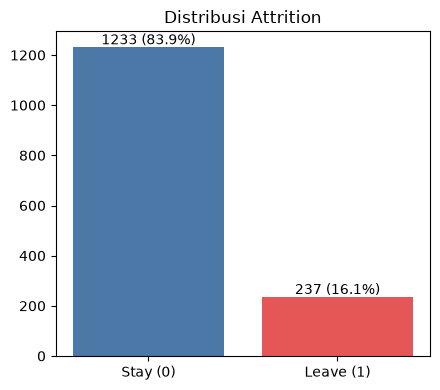

Imbalance ratio (mayoritas:minoritas) = 5.20 : 1


In [9]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.bar(["Stay (0)", "Leave (1)"], counts.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 10, f"{v} ({v/len(tgt):.1%})", ha="center")
ax.set_title("Distribusi Attrition"); plt.tight_layout(); plt.show()
print(f"Imbalance ratio (mayoritas:minoritas) = {counts[0]/counts[1]:.2f} : 1")

### Feature Engineering

In [10]:
# Buang kolom ID/konstan jika masih ada
drop_cols = [c for c in ["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"] if c in df.columns]
df = df.drop(columns=drop_cols)

# Target 0/1 (hanya dikonversi jika masih teks)
if df["Attrition"].isin(["Yes", "No"]).all():
    df["Attrition"] = (df["Attrition"] == "Yes").astype(int)
assert set(df["Attrition"].unique()) <= {0, 1}

# Fitur turunan
df["IncomePerYearExp"] = df["MonthlyIncome"] / (df["TotalWorkingYears"] + 1)
df["PromotionGap"]     = df["YearsSinceLastPromotion"] / (df["YearsAtCompany"] + 1)
df["SatisfactionMean"] = df[["JobSatisfaction", "EnvironmentSatisfaction",
                             "RelationshipSatisfaction", "WorkLifeBalance"]].mean(axis=1)

# Pengelompokan tipe fitur (dipakai seluruh anggota)
CONT = ["Age", "DailyRate", "DistanceFromHome", "HourlyRate", "MonthlyIncome",
        "MonthlyRate", "NumCompaniesWorked", "PercentSalaryHike", "TotalWorkingYears",
        "TrainingTimesLastYear", "YearsAtCompany", "YearsInCurrentRole",
        "YearsSinceLastPromotion", "YearsWithCurrManager",
        "IncomePerYearExp", "PromotionGap", "SatisfactionMean"]
ORD  = ["Education", "EnvironmentSatisfaction", "JobInvolvement", "JobLevel",
        "JobSatisfaction", "PerformanceRating", "RelationshipSatisfaction",
        "StockOptionLevel", "WorkLifeBalance"]
CAT  = ["BusinessTravel", "Department", "EducationField", "Gender",
        "JobRole", "MaritalStatus", "OverTime"]

missing = [c for c in CONT + ORD + CAT if c not in df.columns]
extra   = [c for c in df.columns if c not in CONT + ORD + CAT + ["Attrition"]]
assert not missing, f"Kolom hilang: {missing}"
print("Kolom tidak terpakai:", extra)    # idealnya []

Kolom tidak terpakai: []


### Korelasi Data

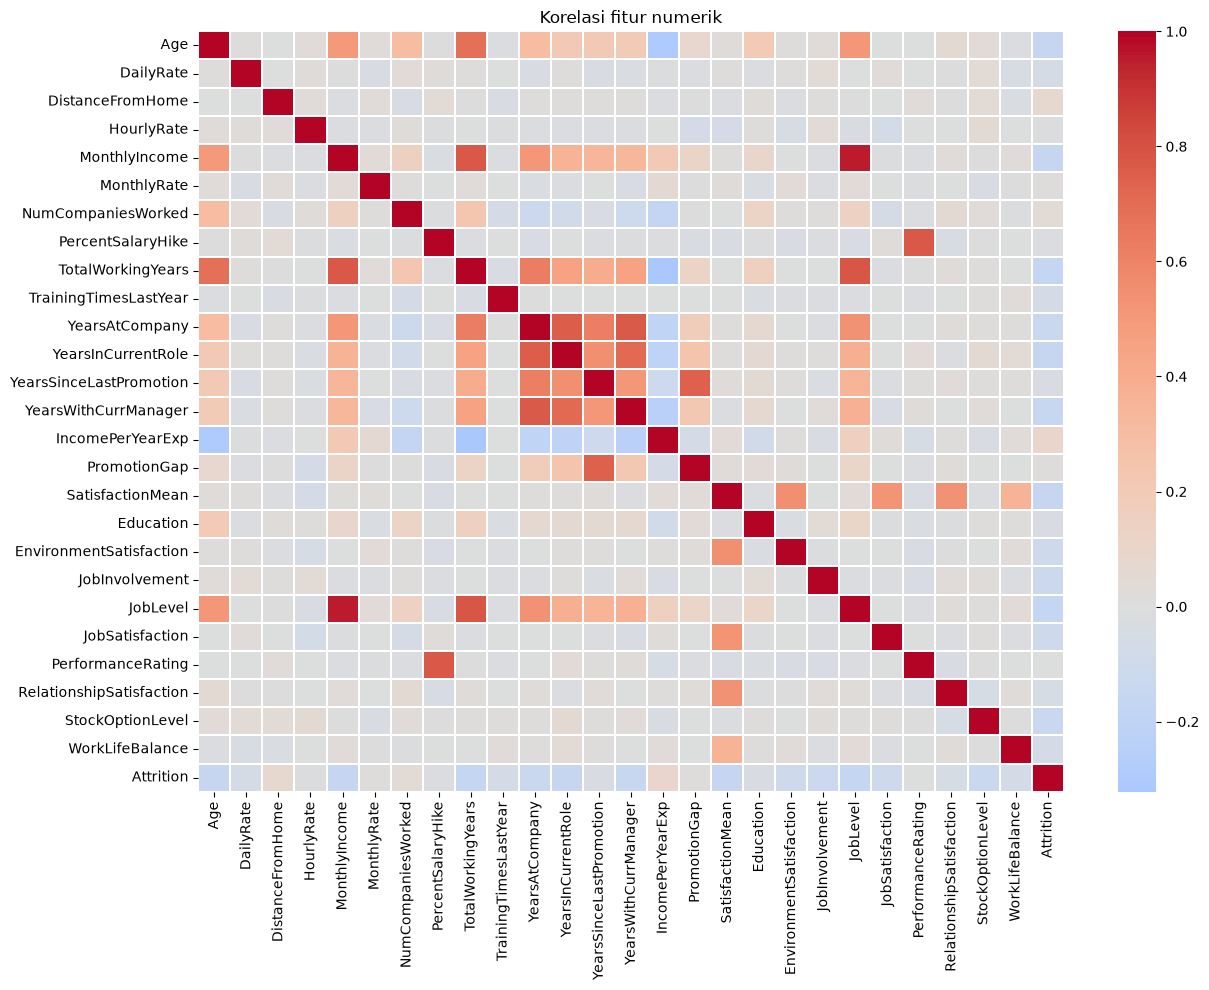

10 fitur paling berkorelasi dengan Attrition:
 TotalWorkingYears      -0.171
JobLevel               -0.169
YearsInCurrentRole     -0.161
MonthlyIncome          -0.160
Age                    -0.159
SatisfactionMean       -0.159
YearsWithCurrManager   -0.156
StockOptionLevel       -0.137
YearsAtCompany         -0.134
JobInvolvement         -0.130
Name: Attrition, dtype: float64

Pasangan korelasi > 0.7:
 MonthlyIncome            JobLevel                0.950
TotalWorkingYears        JobLevel                0.782
PercentSalaryHike        PerformanceRating       0.774
MonthlyIncome            TotalWorkingYears       0.773
YearsAtCompany           YearsWithCurrManager    0.769
                         YearsInCurrentRole      0.759
YearsSinceLastPromotion  PromotionGap            0.745
YearsInCurrentRole       YearsWithCurrManager    0.714
dtype: float64


In [11]:
num_cols = CONT + ORD
corr = df[num_cols + ["Attrition"]].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, linewidths=.3)
plt.title("Korelasi fitur numerik"); plt.tight_layout(); plt.show()

top = corr["Attrition"].drop("Attrition").sort_values(key=abs, ascending=False).head(10)
print("10 fitur paling berkorelasi dengan Attrition:\n", top.round(3))

# Pasangan fitur sangat berkorelasi (indikasi multikolinearitas)
c = corr.drop("Attrition").drop(columns="Attrition").abs()
pairs = (c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
           .sort_values(ascending=False))
print("\nPasangan korelasi > 0.7:\n", pairs[pairs > 0.7].round(3))

                         n_outlier  persen
TrainingTimesLastYear          238   16.19
MonthlyIncome                  114    7.76
YearsSinceLastPromotion        107    7.28
YearsAtCompany                 104    7.07
TotalWorkingYears               63    4.29
NumCompaniesWorked              52    3.54
IncomePerYearExp                43    2.93
SatisfactionMean                36    2.45
YearsInCurrentRole              21    1.43
YearsWithCurrManager            14    0.95
Age                              0    0.00
PercentSalaryHike                0    0.00
HourlyRate                       0    0.00
DailyRate                        0    0.00
MonthlyRate                      0    0.00
DistanceFromHome                 0    0.00
PromotionGap                     0    0.00


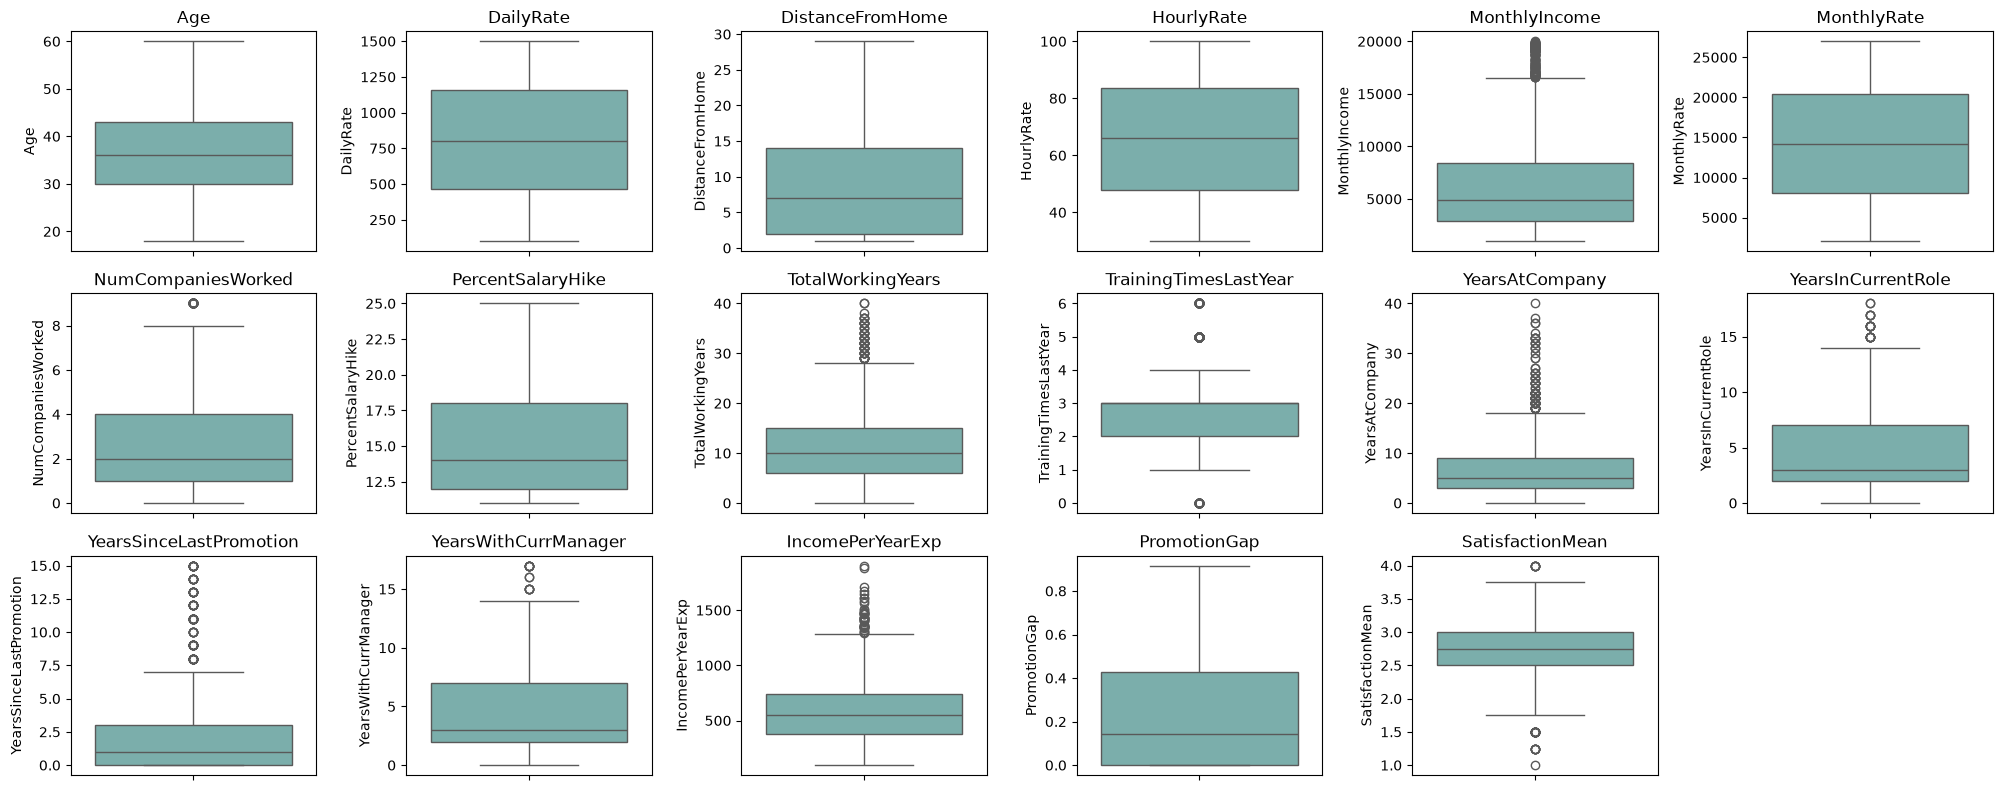

In [12]:
# Outlier (metode IQR): hanya dilaporkan, tidak dibuang
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum()

out_tbl = pd.DataFrame({"n_outlier": {c: iqr_outliers(df[c]) for c in CONT}})
out_tbl["persen"] = (out_tbl["n_outlier"] / len(df) * 100).round(2)
print(out_tbl.sort_values("n_outlier", ascending=False))

fig, axes = plt.subplots(3, 6, figsize=(20, 8)); axes = axes.ravel()
for ax, col in zip(axes, CONT):
    sns.boxplot(y=df[col], ax=ax, color="#72B7B2"); ax.set_title(col)
for ax in axes[len(CONT):]: ax.axis("off")
plt.tight_layout(); plt.show()

# Pembuatan Model

### Split Data

In [13]:
SEED = 42

X = df.drop(columns="Attrition")
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_test = X_train.reset_index(drop=True), X_test.reset_index(drop=True)
y_train, y_test = y_train.reset_index(drop=True), y_test.reset_index(drop=True)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Attrition train:", y_train.mean().round(4), "| test:", y_test.mean().round(4))

Train: (1176, 33) | Test: (294, 33)
Attrition train: 0.1616 | test: 0.1599


### Pembuatan Fungsi Model Baseline dan Pipeline

In [14]:
def make_preprocessor(extra_num=()):
    """Scaling fitur numerik + one-hot kategorikal. Di-fit hanya pada data train tiap fold."""
    return ColumnTransformer([
        ("num", StandardScaler(), CONT + ORD + list(extra_num)),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

def make_model(name, class_weight=None):
    if name == "LogReg":
        return LogisticRegression(max_iter=2000, class_weight=class_weight, random_state=SEED)
    if name == "RandForest":      # parameter default (baseline)
        return RandomForestClassifier(class_weight=class_weight, random_state=SEED, n_jobs=-1)
    raise ValueError(name)

def build_pipeline(model_name, imb=None):
    """
    imb: None | 'cw' (class weight) | 'smote'
    Resampling berada DI DALAM pipeline: hanya dijalankan saat fit (data train fold),
    tidak pernah menyentuh data validasi.
    """
    steps = [("pre", make_preprocessor())]
    if imb == "smote":
        steps.append(("smote", SMOTE(random_state=SEED)))
    cw = "balanced" if imb == "cw" else None
    steps.append(("clf", make_model(model_name, class_weight=cw)))
    return ImbPipeline(steps)

### Pembuatan Fungsi Cross Validation dan Metrik Evaluasi

In [15]:
SCORING = {
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall":    make_scorer(recall_score),
    "F1":        make_scorer(f1_score),
    "BalAcc":    make_scorer(balanced_accuracy_score),
    "ROC_AUC":   "roc_auc",
    "PR_AUC":    "average_precision",
}

def get_cv(n_splits=5):
    return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)

def run_cv(pipeline, X, y, n_splits=5):
    """Stratified k-fold. Mengembalikan rata-rata dan simpangan baku tiap metrik."""
    res = cross_validate(pipeline, X, y, cv=get_cv(n_splits), scoring=SCORING,
                         n_jobs=1, error_score="raise")
    out = {}
    for m in SCORING:
        out[m] = res[f"test_{m}"].mean()
        out[f"{m}_std"] = res[f"test_{m}"].std()
    return out

def oof_proba(pipeline, X, y, n_splits=5):
    """Probabilitas out-of-fold (untuk threshold tuning)."""
    return cross_val_predict(pipeline, X, y, cv=get_cv(n_splits), method="predict_proba")[:, 1]

def compute_metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"Precision": precision_score(y_true, pred, zero_division=0),
            "Recall":    recall_score(y_true, pred),
            "F1":        f1_score(y_true, pred),
            "BalAcc":    balanced_accuracy_score(y_true, pred),
            "ROC_AUC":   roc_auc_score(y_true, proba),
            "PR_AUC":    average_precision_score(y_true, proba)}

### Menampilkan Hasil Smote Pada Data Train

,Sebelum,Sesudah SMOTE,Sintetis ditambahkan
Stay (0),986,986,0
Leave (1),190,986,796


Proporsi Leave: 16.2% -> 50.0%


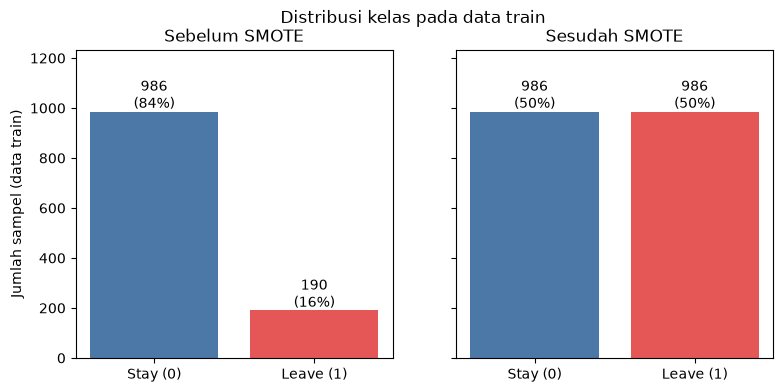

In [16]:
from imblearn.over_sampling import SMOTE

pre = make_preprocessor()
Xp = pre.fit_transform(X_train)                       # fit di data train saja
Xs, ys = SMOTE(random_state=SEED).fit_resample(Xp, y_train)

# Tabel ringkas
before = y_train.value_counts().sort_index()
after = pd.Series(ys).value_counts().sort_index()
tbl = pd.DataFrame({"Sebelum": before, "Sesudah SMOTE": after}, index=[0, 1])
tbl.index = ["Stay (0)", "Leave (1)"]
tbl["Sintetis ditambahkan"] = tbl["Sesudah SMOTE"] - tbl["Sebelum"]
display(tbl)
print(f"Proporsi Leave: {before[1]/before.sum():.1%} -> {after[1]/after.sum():.1%}")

# Grafik
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, (name, c) in zip(axes, [("Sebelum SMOTE", before), ("Sesudah SMOTE", after)]):
    ax.bar(["Stay (0)", "Leave (1)"], c.values, color=["#4C78A8", "#E45756"])
    for i, v in enumerate(c.values):
        ax.text(i, v + 15, f"{v}\n({v/c.sum():.0%})", ha="center")
    ax.set_title(name); ax.set_ylim(0, after.max() * 1.25)
axes[0].set_ylabel("Jumlah sampel (data train)")
plt.suptitle("Distribusi kelas pada data train")
plt.show()

### Train Model Baseline

In [17]:
IMB_OPTIONS = {"Tanpa penanganan": None, "Class weight": "cw", "SMOTE": "smote"}
rows = []
for model_name in ["LogReg", "RandForest"]:
    for imb_name, imb in IMB_OPTIONS.items():
        r = run_cv(build_pipeline(model_name, imb), X_train, y_train)
        r.update(Model=model_name, Imbalance=imb_name)
        rows.append(r)
        print(f"{model_name:10s} | {imb_name:17s} | F1={r['F1']:.3f}±{r['F1_std']:.3f} "
              f"Recall={r['Recall']:.3f} PR_AUC={r['PR_AUC']:.3f}")
        
cv_baseline = pd.DataFrame(rows)

# Tabel ringkas mean ± std
show = cv_baseline[["Model", "Imbalance"]].copy()
for m in ["Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]:
    show[m] = cv_baseline.apply(lambda r: f"{r[m]:.3f} ± {r[m+'_std']:.3f}", axis=1)
display(show)

LogReg     | Tanpa penanganan  | F1=0.570±0.080 Recall=0.453 PR_AUC=0.667
LogReg     | Class weight      | F1=0.488±0.025 Recall=0.732 PR_AUC=0.624
LogReg     | SMOTE             | F1=0.495±0.029 Recall=0.700 PR_AUC=0.608
RandForest | Tanpa penanganan  | F1=0.336±0.108 Recall=0.221 PR_AUC=0.570
RandForest | Class weight      | F1=0.456±0.082 Recall=0.363 PR_AUC=0.551
RandForest | SMOTE             | F1=0.429±0.071 Recall=0.311 PR_AUC=0.571


,Model,Imbalance,Precision,Recall,F1,ROC_AUC,PR_AUC
0,LogReg,Tanpa penanganan,0.779 ± 0.069,0.453 ± 0.082,0.570 ± 0.080,0.841 ± 0.030,0.667 ± 0.059
1,LogReg,Class weight,0.368 ± 0.026,0.732 ± 0.071,0.488 ± 0.025,0.829 ± 0.031,0.624 ± 0.077
2,LogReg,SMOTE,0.384 ± 0.023,0.700 ± 0.079,0.495 ± 0.029,0.826 ± 0.032,0.608 ± 0.068
3,RandForest,Tanpa penanganan,0.842 ± 0.098,0.221 ± 0.091,0.336 ± 0.108,0.817 ± 0.030,0.570 ± 0.047
4,RandForest,Class weight,0.638 ± 0.111,0.363 ± 0.084,0.456 ± 0.082,0.801 ± 0.034,0.551 ± 0.071
5,RandForest,SMOTE,0.748 ± 0.113,0.311 ± 0.071,0.429 ± 0.071,0.814 ± 0.036,0.571 ± 0.048


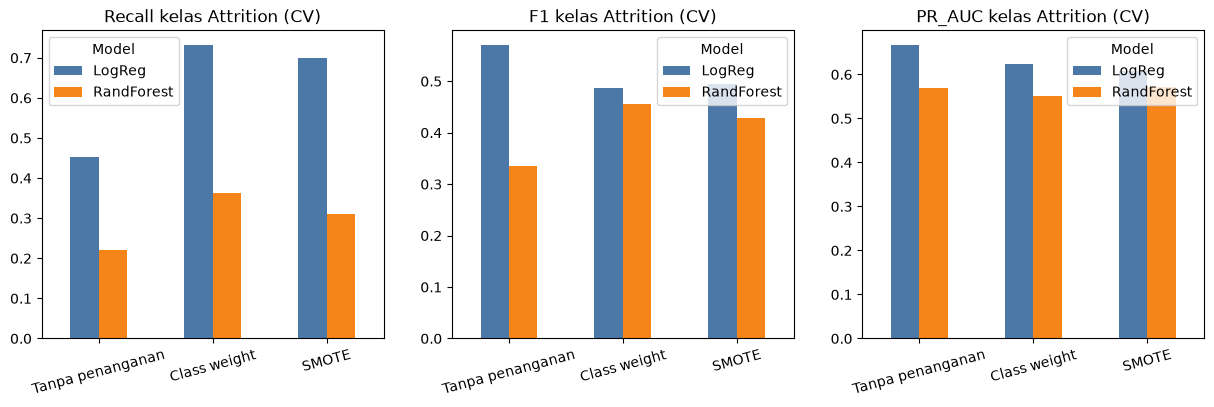

In [18]:
# Visualisasi before/after imbalance handling
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["Recall", "F1", "PR_AUC"]):
    piv = cv_baseline.pivot(index="Imbalance", columns="Model", values=metric).loc[list(IMB_OPTIONS)]
    piv.plot(kind="bar", ax=ax, rot=15, color=["#4C78A8", "#F58518"])
    ax.set_title(f"{metric} kelas Attrition (CV)"); ax.set_xlabel("")

In [19]:
test_rows = []
for model_name in ["LogReg", "RandForest"]:
    for imb_name, imb in IMB_OPTIONS.items():
        pipe = build_pipeline(model_name, imb).fit(X_train, y_train)
        r = compute_metrics(y_test, pipe.predict_proba(X_test)[:, 1])
        r.update(Model=model_name, Imbalance=imb_name)
        test_rows.append(r)

test_baseline = pd.DataFrame(test_rows)[["Model", "Imbalance", "Precision", "Recall", "F1", "BalAcc", "ROC_AUC", "PR_AUC"]]
display(test_baseline.round(3))

,Model,Imbalance,Precision,Recall,F1,BalAcc,ROC_AUC,PR_AUC
0,LogReg,Tanpa penanganan,0.593,0.340,0.432,0.648,0.818,0.581
1,LogReg,Class weight,0.367,0.617,0.460,0.707,0.809,0.558
2,LogReg,SMOTE,0.382,0.617,0.472,0.713,0.808,0.553
3,RandForest,Tanpa penanganan,0.538,0.149,0.233,0.562,0.775,0.435
4,RandForest,Class weight,0.452,0.298,0.359,0.615,0.785,0.439
5,RandForest,SMOTE,0.619,0.277,0.382,0.622,0.790,0.499


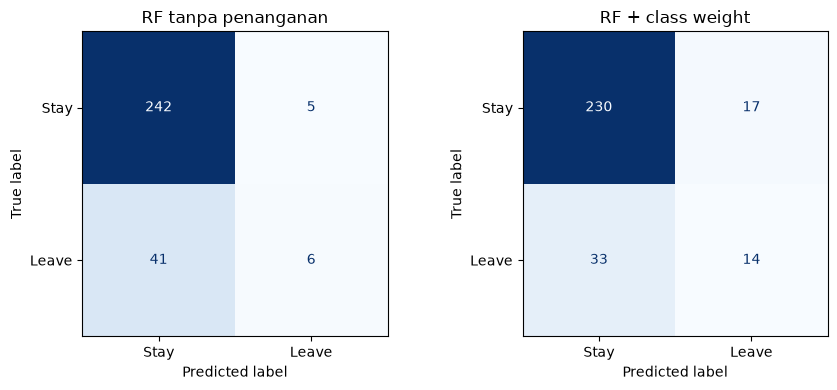

In [20]:
# Confusion matrix baseline (RF default tanpa penanganan vs RF + class weight)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, imb) in zip(axes, [("RF tanpa penanganan", None), ("RF + class weight", "cw")]):
    pipe = build_pipeline("RandForest", imb).fit(X_train, y_train)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pipe.predict(X_test)),
                           display_labels=["Stay", "Leave"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title)
plt.tight_layout(); plt.show()

#Fuzzy C Means (Segmentasi Profil)

In [21]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import silhouette_score

# Fitur untuk segmentasi (tanpa DailyRate/HourlyRate/MonthlyRate yang hampir acak)
CLUSTER_FEATS = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
                 "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager",
                 "NumCompaniesWorked", "DistanceFromHome", "SatisfactionMean"]
M_FCM = 1.5   # m=2 membuat FCM runtuh di data ini

def _dist(data, V):
    return np.maximum(np.linalg.norm(data[:, None, :] - V[None, :, :], axis=2), 1e-10)

def _update_U(data, V, m):
    inv = _dist(data, V) ** (-2.0 / (m - 1))
    return inv / inv.sum(axis=1, keepdims=True)

def _kmeanspp_init(data, c, rng):
    V = [data[rng.integers(len(data))]]
    for _ in range(c - 1):
        d2 = np.min(np.linalg.norm(data[:, None, :] - np.array(V)[None], axis=2) ** 2, axis=1)
        V.append(data[rng.choice(len(data), p=d2 / d2.sum())])
    return np.array(V)

def fuzzy_c_means(data, c=3, m=2.0, max_iter=300, error=1e-6, seed=42, n_init=5):
    best = None
    for k in range(n_init):                      # multi-start, ambil objektif J terkecil
        rng = np.random.default_rng(seed + k)
        V = _kmeanspp_init(data, c, rng)
        U = _update_U(data, V, m)
        for _ in range(max_iter):
            U_old = U.copy()
            um = U ** m
            V = (um.T @ data) / um.sum(axis=0)[:, None]
            U = _update_U(data, V, m)
            if np.abs(U - U_old).max() < error:
                break
        J = np.sum((U ** m) * _dist(data, V) ** 2)
        if best is None or J < best[0]:
            best = (J, U, V)
    return best[1], best[2]

def fcm_predict(data, V, m=2.0):
    return _update_U(data, V, m)

def fpc(U):
    return np.sum(U ** 2) / U.shape[0]

def xie_beni(data, U, V, m=2.0):
    n, c = U.shape
    num = np.sum((U ** m) * _dist(data, V) ** 2)
    sep = min(np.sum((V[i] - V[j]) ** 2) for i in range(c) for j in range(i + 1, c))
    return num / (n * sep)

class FCMMembership(BaseEstimator, TransformerMixin):
    """FCM sebagai transformer: fit di data train fold, transform data validasi (tanpa leakage)."""
    def __init__(self, c=3, m=2.0, seed=42):
        self.c, self.m, self.seed = c, m, seed
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.scaler_ = StandardScaler().fit(X)
        _, self.V_ = fuzzy_c_means(self.scaler_.transform(X), self.c, self.m, seed=self.seed)
        return self
    def transform(self, X):
        return fcm_predict(self.scaler_.transform(np.asarray(X, dtype=float)), self.V_, self.m)

In [22]:
Xs = StandardScaler().fit_transform(df[CLUSTER_FEATS])
hasil = []
for c in [2, 3, 4, 5, 6]:
    U, V = fuzzy_c_means(Xs, c, m=M_FCM)
    lab = U.argmax(1)
    hasil.append({"c": c, "FPC": fpc(U), "Xie-Beni": xie_beni(Xs, U, V, M_FCM),
                  "Silhouette": silhouette_score(Xs, lab),
                  "Ukuran cluster": np.bincount(lab, minlength=c).tolist()})
display(pd.DataFrame(hasil).round(3))

,c,FPC,Xie-Beni,Silhouette,Ukuran cluster
0,2,0.758,0.649,0.268,"[947, 523]"
1,3,0.575,1.760,0.170,"[613, 372, 485]"
2,4,0.540,1.185,0.181,"[432, 181, 378, 479]"
3,5,0.480,1.493,0.172,"[353, 425, 154, 370, 168]"
4,6,0.453,1.238,0.172,"[231, 332, 136, 339, 136, 296]"


,Age,MonthlyIncome,TotalWorkingYears,YearsAtCompany,Attrition,n
FCM_Cluster,,,,,,
0,34.23,4516.82,7.60,3.89,0.2,947
1,41.80,10099.20,17.95,12.65,0.1,523


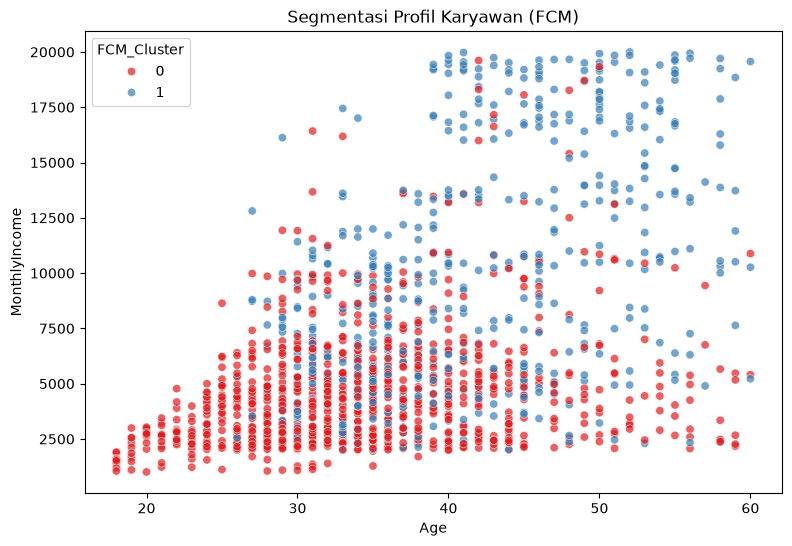

In [23]:
Xs = StandardScaler().fit_transform(df[CLUSTER_FEATS])
best_c = 2   # sesuaikan dengan keputusanmu dari tabel B2
U_final, V_final = fuzzy_c_means(Xs, best_c, m=M_FCM)
df["FCM_Cluster"] = U_final.argmax(1)

profil = df.groupby("FCM_Cluster")[["Age", "MonthlyIncome", "TotalWorkingYears",
                                    "YearsAtCompany", "Attrition"]].mean().round(2)
profil["n"] = df["FCM_Cluster"].value_counts().sort_index()
display(profil)

plt.figure(figsize=(9, 6))
sns.scatterplot(x=df["Age"], y=df["MonthlyIncome"], hue=df["FCM_Cluster"], palette="Set1", alpha=0.7)
plt.title("Segmentasi Profil Karyawan (FCM)"); plt.show()

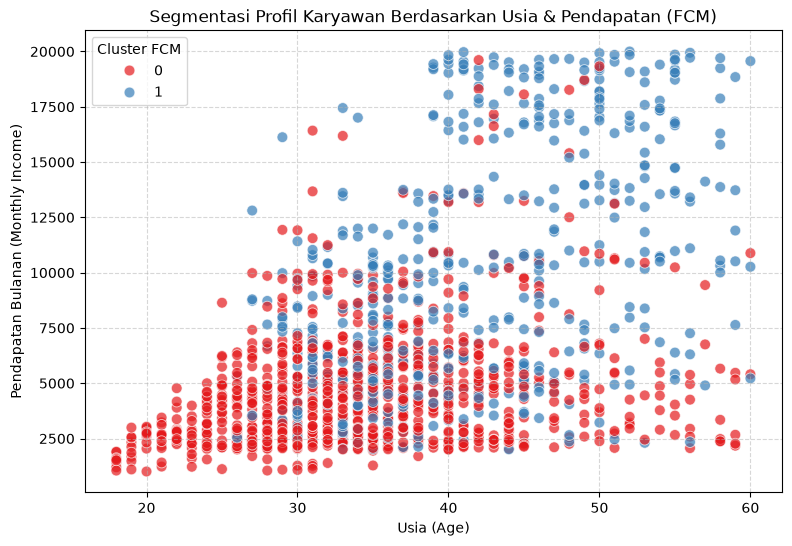

In [24]:
### 4. Visualisasi Sebaran Cluster FCM
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=df['Age'], 
    y=df['MonthlyIncome'], 
    hue=df['FCM_Cluster'], 
    palette='Set1', 
    alpha=0.7,
    s=60
)
plt.title("Segmentasi Profil Karyawan Berdasarkan Usia & Pendapatan (FCM)")
plt.xlabel("Usia (Age)")
plt.ylabel("Pendapatan Bulanan (Monthly Income)")
plt.legend(title="Cluster FCM")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [25]:
def build_pipeline_fcm(model_name, imb=None, use_fcm=False, c=3):
    tr = [("num", StandardScaler(), CONT + ORD),
          ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)]
    if use_fcm:
        tr.append(("fcm", FCMMembership(c=c, m=M_FCM, seed=SEED), CLUSTER_FEATS))
    steps = [("pre", ColumnTransformer(tr))]
    if imb == "smote":
        steps.append(("smote", SMOTE(random_state=SEED)))
    steps.append(("clf", make_model(model_name)))
    return ImbPipeline(steps)

rows = []
for model in ["LogReg", "RandForest"]:
    for imb_name, imb in {"Tanpa penanganan": None, "SMOTE": "smote"}.items():
        for use in [False, True]:
            r = run_cv(build_pipeline_fcm(model, imb, use, best_c), X_train, y_train)
            r.update(Model=model, Imbalance=imb_name, FCM="Dengan" if use else "Tanpa")
            rows.append(r)

abl = pd.DataFrame(rows)
tampil = abl[["Model", "Imbalance", "FCM"]].copy()
for m in ["Recall", "F1", "PR_AUC", "ROC_AUC"]:
    tampil[m] = abl.apply(lambda r: f"{r[m]:.3f} ± {r[m+'_std']:.3f}", axis=1)
display(tampil)

,Model,Imbalance,FCM,Recall,F1,PR_AUC,ROC_AUC
0,LogReg,Tanpa penanganan,Tanpa,0.453 ± 0.082,0.570 ± 0.080,0.667 ± 0.059,0.841 ± 0.030
1,LogReg,Tanpa penanganan,Dengan,0.479 ± 0.077,0.590 ± 0.077,0.671 ± 0.057,0.843 ± 0.029
2,LogReg,SMOTE,Tanpa,0.700 ± 0.079,0.495 ± 0.029,0.608 ± 0.068,0.826 ± 0.032
3,LogReg,SMOTE,Dengan,0.711 ± 0.073,0.514 ± 0.033,0.622 ± 0.064,0.832 ± 0.031
4,RandForest,Tanpa penanganan,Tanpa,0.221 ± 0.091,0.336 ± 0.108,0.570 ± 0.047,0.817 ± 0.030
5,RandForest,Tanpa penanganan,Dengan,0.200 ± 0.089,0.311 ± 0.119,0.535 ± 0.078,0.800 ± 0.044
6,RandForest,SMOTE,Tanpa,0.311 ± 0.071,0.429 ± 0.071,0.571 ± 0.048,0.814 ± 0.036
7,RandForest,SMOTE,Dengan,0.321 ± 0.073,0.450 ± 0.080,0.592 ± 0.040,0.815 ± 0.033


### Ensemble Learning + Genetic Algoritm

In [26]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
import time
import random

import xgboost as xgb
from xgboost import XGBClassifier

# Pastikan bagian anggota 1 sudah dijalankan (variabel dan fungsi bersama)
dibutuhkan = ["X_train", "X_test", "y_train", "y_test",
              "CONT", "ORD", "CAT", "SEED", "SCORING", "run_cv", "get_cv"]
hilang = [n for n in dibutuhkan if n not in globals()]
assert not hilang, f"Jalankan dulu cell anggota 1, belum ada: {hilang}"

print("XGBoost :", xgb.__version__)
print("Pandas  :", pd.__version__)
print("Train   :", X_train.shape, "| Test:", X_test.shape)
print("Attrition di train:", round(y_train.mean(), 4))

XGBoost : 3.2.0
Pandas  : 3.0.6
Train   : (1176, 33) | Test: (294, 33)
Attrition di train: 0.1616


### Baseline XGBoost

In [28]:
def build_ens_pipeline(model, imb=None):
    """Preprocessing -> (SMOTE opsional) -> model. Semua langkah di dalam fold CV."""
    pre = ColumnTransformer([
        ("num", StandardScaler(), CONT + ORD),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    steps = [("pre", pre)]
    if imb == "smote":
        steps.append(("smote", SMOTE(random_state=SEED)))
    steps.append(("clf", model))
    return ImbPipeline(steps)

def xgb_default(**kw):
    return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss", **kw)

# Rasio kelas negatif : positif pada data latih, untuk scale_pos_weight
spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight =", round(spw, 3))

scale_pos_weight = 5.189


##### Hasil Cross-Validation Baseline

In [29]:
skenario = {
    "XGB default | tanpa penanganan": (xgb_default(), None),
    "XGB default | scale_pos_weight": (xgb_default(scale_pos_weight=spw), None),
    "XGB default | SMOTE":            (xgb_default(), "smote"),
}

rows = []
for nama, (model, imb) in skenario.items():
    t = time.time()
    r = run_cv(build_ens_pipeline(model, imb), X_train, y_train)
    r["Skenario"] = nama
    r["Waktu (dtk)"] = round(time.time() - t, 1)
    rows.append(r)

hasil_xgb = pd.DataFrame(rows)
tampil = hasil_xgb[["Skenario"]].copy()
for m in ["Recall", "F1", "PR_AUC", "ROC_AUC"]:
    tampil[m] = hasil_xgb.apply(lambda r: f"{r[m]:.3f} ± {r[m+'_std']:.3f}", axis=1)
tampil["Waktu (dtk)"] = hasil_xgb["Waktu (dtk)"]
display(tampil)

,Skenario,Recall,F1,PR_AUC,ROC_AUC,Waktu (dtk)
0,XGB default | tanpa penanganan,0.332 ± 0.046,0.450 ± 0.036,0.569 ± 0.035,0.804 ± 0.028,0.5
1,XGB default | scale_pos_weight,0.400 ± 0.071,0.491 ± 0.075,0.564 ± 0.059,0.797 ± 0.024,0.5
2,XGB default | SMOTE,0.374 ± 0.077,0.471 ± 0.074,0.570 ± 0.056,0.804 ± 0.031,0.9


### Ruang Pencarian Hyperparameter dan Fungsi Fitness

In [30]:
# (tipe, batas bawah, batas atas); "log" = dicari pada skala logaritmik
SEARCH_SPACE = {
    "n_estimators":     ("int",   50,    500),
    "max_depth":        ("int",   2,     10),
    "learning_rate":    ("log",   0.01,  0.3),
    "subsample":        ("float", 0.5,   1.0),
    "colsample_bytree": ("float", 0.5,   1.0),
    "min_child_weight": ("int",   1,     10),
    "gamma":            ("float", 0.0,   5.0),
    "reg_lambda":       ("log",   0.1,   10.0),
    "reg_alpha":        ("log",   0.001, 10.0),
    "scale_pos_weight": ("float", 1.0,   10.0),   # rasio kelas di data latih = 5,19
}
PARAM_NAMES = list(SEARCH_SPACE)
N_GENES = len(PARAM_NAMES)

FITNESS_METRIC = "PR_AUC"   # bisa diganti "F1" atau "Recall"

def decode(vec):
    """Vektor gen [0,1]^N -> dict hyperparameter XGBoost."""
    params = {}
    for g, name in zip(vec, PARAM_NAMES):
        kind, lo, hi = SEARCH_SPACE[name]
        g = float(np.clip(g, 0.0, 1.0))
        if kind == "log":
            v = float(np.exp(np.log(lo) + g * (np.log(hi) - np.log(lo))))
        else:
            v = lo + g * (hi - lo)
        params[name] = int(round(v)) if kind == "int" else float(v)
    return params

print("Jumlah gen:", N_GENES)
print("Titik tengah ruang pencarian:")
display(pd.Series(decode(np.full(N_GENES, 0.5))))

Jumlah gen: 10
Titik tengah ruang pencarian:


n_estimators        275.000000
max_depth             6.000000
learning_rate         0.054772
subsample             0.750000
colsample_bytree      0.750000
min_child_weight      6.000000
gamma                 2.500000
reg_lambda            1.000000
reg_alpha             0.100000
scale_pos_weight      5.500000
dtype: float64

##### Fungsi Evaluasi (Fitness)

In [31]:
def make_xgb(params):
    return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss", **params)

class Evaluator:
    """Menghitung fitness, mencatat riwayat, dan menghitung jumlah evaluasi model yang sebenarnya."""
    def __init__(self, metric=FITNESS_METRIC):
        self.metric, self.cache, self.history = metric, {}, []

    def __call__(self, vec):
        params = decode(vec)
        key = tuple((k, round(v, 6)) for k, v in sorted(params.items()))
        if key in self.cache:                       # kandidat sama: tidak dihitung ulang
            return self.cache[key]
        r = run_cv(build_ens_pipeline(make_xgb(params)), X_train, y_train)
        score = r[self.metric]
        self.cache[key] = score
        self.history.append({"eval": len(self.history) + 1, "score": score,
                             "F1": r["F1"], "Recall": r["Recall"], **params})
        return score

    @property
    def n_evals(self):
        return len(self.history)

##### Uji Coba Fungsi Fitness

In [32]:
uji = Evaluator()
rng = np.random.default_rng(SEED)

t = time.time()
s_tengah = uji(np.full(N_GENES, 0.5))
print(f"Skor titik tengah ({FITNESS_METRIC}): {s_tengah:.4f} | waktu: {time.time()-t:.1f} dtk")
print("Evaluasi ulang memakai cache:", uji(np.full(N_GENES, 0.5)) == s_tengah, "| n_evals =", uji.n_evals)

for _ in range(5):
    uji(rng.random(N_GENES))
display(pd.DataFrame(uji.history)[["eval", "score", "F1", "Recall", "n_estimators",
                                   "max_depth", "learning_rate", "scale_pos_weight"]].round(3))

Skor titik tengah (PR_AUC): 0.6264 | waktu: 0.7 dtk
Evaluasi ulang memakai cache: True | n_evals = 1


,eval,score,F1,Recall,n_estimators,max_depth,learning_rate,scale_pos_weight
0,1,0.626,0.544,0.532,275,6,0.055,5.500
1,2,0.600,0.524,0.563,398,6,0.185,5.053
2,3,0.592,0.541,0.568,217,9,0.089,6.685
3,4,0.549,0.523,0.532,391,5,0.272,7.147
4,5,0.613,0.529,0.468,385,10,0.030,7.028
5,6,0.606,0.546,0.484,247,9,0.108,2.258


### Random Search

In [33]:
import os

BUDGET = 200            # jumlah evaluasi model per run (sama untuk Random Search dan GA)
SEEDS = [42, 43, 44]    # pengulangan untuk menguji kestabilan
os.makedirs("hasil_search", exist_ok=True)

def random_search(budget, seed):
    rng = np.random.default_rng(seed)
    ev = Evaluator()
    t = time.time()
    while ev.n_evals < budget:
        ev(rng.random(N_GENES))
    ev.waktu = time.time() - t
    return ev

In [34]:
rs_runs = {}
for seed in SEEDS:
    ev = random_search(BUDGET, seed)
    rs_runs[seed] = ev
    pd.DataFrame(ev.history).to_csv(f"hasil_search/rs_seed{seed}.csv", index=False)
    print(f"Seed {seed}: {ev.n_evals} evaluasi | best {FITNESS_METRIC} = "
          f"{max(h['score'] for h in ev.history):.4f} | {ev.waktu/60:.1f} menit", flush=True)

Seed 42: 200 evaluasi | best PR_AUC = 0.6386 | 2.4 menit
Seed 43: 200 evaluasi | best PR_AUC = 0.6514 | 2.5 menit
Seed 44: 200 evaluasi | best PR_AUC = 0.6334 | 2.5 menit


##### Ringkasan & Konvergensi

,Seed,Best PR_AUC (CV),F1,Recall,scale_pos_weight,max_depth,learning_rate,n_estimators
0,42,0.639,0.537,0.437,1.835,7.0,0.164,66.0
1,43,0.651,0.515,0.379,1.127,10.0,0.067,482.0
2,44,0.633,0.523,0.405,1.101,3.0,0.133,450.0


Rata-rata best: 0.6411 ± 0.0092


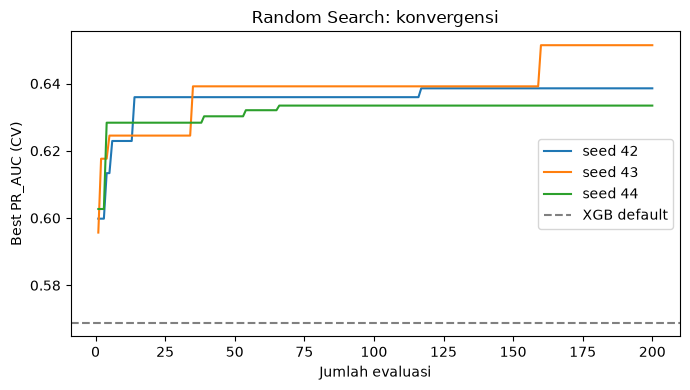

Kandidat yang mengalahkan default: 94.3%


In [35]:
ringkas = []
for seed, ev in rs_runs.items():
    h = pd.DataFrame(ev.history)
    b = h.loc[h["score"].idxmax()]
    ringkas.append({"Seed": seed, "Best PR_AUC (CV)": b["score"], "F1": b["F1"],
                    "Recall": b["Recall"], "scale_pos_weight": b["scale_pos_weight"],
                    "max_depth": b["max_depth"], "learning_rate": b["learning_rate"],
                    "n_estimators": b["n_estimators"]})
ringkas = pd.DataFrame(ringkas)
display(ringkas.round(3))
print(f"Rata-rata best: {ringkas['Best PR_AUC (CV)'].mean():.4f} ± {ringkas['Best PR_AUC (CV)'].std():.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
for seed, ev in rs_runs.items():
    s = pd.Series([h["score"] for h in ev.history]).cummax()
    ax.plot(range(1, len(s) + 1), s, label=f"seed {seed}")
ax.axhline(hasil_xgb.loc[0, "PR_AUC"], color="gray", ls="--", label="XGB default")
ax.set_xlabel("Jumlah evaluasi"); ax.set_ylabel(f"Best {FITNESS_METRIC} (CV)")
ax.set_title("Random Search: konvergensi"); ax.legend(); plt.tight_layout(); plt.show()

semua = pd.concat([pd.DataFrame(e.history) for e in rs_runs.values()])
print(f"Kandidat yang mengalahkan default: {(semua['score'] > hasil_xgb.loc[0, 'PR_AUC']).mean():.1%}")

##### Genetic Algorithm (Single-Objective)

In [36]:
POP_SIZE = 20        # ukuran populasi
ELITE = 2            # individu terbaik yang dibawa langsung
TOURN_K = 3          # ukuran turnamen seleksi
P_CROSSOVER = 0.9
BLX_ALPHA = 0.3      # perluasan rentang pada BLX-alpha
P_MUTATION = 0.15    # peluang mutasi per gen
SIGMA_MUT = 0.15     # simpangan baku mutasi (skala gen 0-1)

def tournament_select(pop, fit, rng, k=TOURN_K):
    idx = rng.choice(len(pop), size=k, replace=False)
    return pop[idx[np.argmax(fit[idx])]].copy()

def crossover_blx(p1, p2, rng, alpha=BLX_ALPHA):
    d = np.abs(p1 - p2)
    lo = np.minimum(p1, p2) - alpha * d
    hi = np.maximum(p1, p2) + alpha * d
    return np.clip(rng.uniform(lo, hi), 0.0, 1.0)

def mutate(ind, rng, p=P_MUTATION, sigma=SIGMA_MUT):
    ind = ind.copy()
    mask = rng.random(len(ind)) < p
    ind[mask] += rng.normal(0.0, sigma, mask.sum())
    return np.clip(ind, 0.0, 1.0)

##### Fungsi Genetic Algorithm

In [37]:
def genetic_algorithm(budget, seed, pop_size=POP_SIZE, elite=ELITE):
    rng = np.random.default_rng(seed)
    ev = Evaluator()
    t = time.time()

    # Generasi 0: populasi acak
    pop = rng.random((pop_size, N_GENES))
    fit = np.array([ev(ind) for ind in pop])
    ev.gen_log = [{"generasi": 0, "best": float(fit.max()), "mean": float(fit.mean()),
                   "n_evals": ev.n_evals}]

    percobaan = 0
    batas = budget * 20                       # pengaman agar tidak berputar tanpa akhir
    gen = 0
    while ev.n_evals < budget and percobaan < batas:
        gen += 1
        urut = np.argsort(-fit)
        new_pop = [pop[i].copy() for i in urut[:elite]]      # elitisme (tidak dievaluasi ulang)
        new_fit = [fit[i] for i in urut[:elite]]
        while len(new_pop) < pop_size and ev.n_evals < budget and percobaan < batas:
            percobaan += 1
            p1 = tournament_select(pop, fit, rng)
            p2 = tournament_select(pop, fit, rng)
            child = crossover_blx(p1, p2, rng) if rng.random() < P_CROSSOVER else p1.copy()
            child = mutate(child, rng)
            new_pop.append(child)
            new_fit.append(ev(child))
        pop, fit = np.array(new_pop), np.array(new_fit)
        ev.gen_log.append({"generasi": gen, "best": float(fit.max()), "mean": float(fit.mean()),
                           "n_evals": ev.n_evals})

    ev.waktu = time.time() - t
    return ev

##### Menjalankan GA

In [38]:
from types import SimpleNamespace

RERUN_GA = True   # False = muat dari hasil_search/ga_seed*.csv jika sudah ada (hemat waktu)

def muat_ga_csv(seed):
    h = pd.read_csv(f"hasil_search/ga_seed{seed}.csv")
    p_gen = f"hasil_search/ga_generasi_seed{seed}.csv"
    g = pd.read_csv(p_gen) if os.path.exists(p_gen) else pd.DataFrame()
    return SimpleNamespace(history=h.to_dict("records"), gen_log=g.to_dict("records"),
                           waktu=float("nan"), n_evals=len(h))

ga_runs = {}
for seed in SEEDS:
    path = f"hasil_search/ga_seed{seed}.csv"
    if (not RERUN_GA) and os.path.exists(path):
        ga_runs[seed] = muat_ga_csv(seed)
        print(f"Seed {seed}: dimuat dari CSV ({ga_runs[seed].n_evals} evaluasi)")
        continue
    ev = genetic_algorithm(BUDGET, seed)
    ga_runs[seed] = ev
    pd.DataFrame(ev.history).to_csv(path, index=False)
    pd.DataFrame(ev.gen_log).to_csv(f"hasil_search/ga_generasi_seed{seed}.csv", index=False)
    print(f"Seed {seed}: {ev.n_evals} evaluasi | best {FITNESS_METRIC} = "
          f"{max(h['score'] for h in ev.history):.4f} | {ev.waktu/60:.1f} menit", flush=True)

Seed 42: 200 evaluasi | best PR_AUC = 0.6563 | 2.1 menit
Seed 43: 200 evaluasi | best PR_AUC = 0.6639 | 2.6 menit
Seed 44: 200 evaluasi | best PR_AUC = 0.6602 | 2.2 menit


##### Ringkasan Hasil dan Konvergensi GA

,Seed,Best PR_AUC (CV),F1,Recall,scale_pos_weight,max_depth,learning_rate,n_estimators
0,42,0.656,0.502,0.368,1.535,2.0,0.033,237.0
1,43,0.664,0.523,0.379,1.000,2.0,0.068,311.0
2,44,0.660,0.465,0.321,1.013,9.0,0.093,396.0


Rata-rata best: 0.6601 ± 0.0038

Riwayat per generasi (seed 42):


,generasi,best,mean,n_evals
0,0,0.6359,0.5999,20
1,1,0.6359,0.6110,38
2,2,0.6384,0.6155,55
3,3,0.6497,0.6263,72
4,4,0.6497,0.6378,87
5,5,0.6497,0.6387,104
6,6,0.6507,0.6402,122
7,7,0.6521,0.6408,140
8,8,0.6521,0.6435,158
9,9,0.6530,0.6430,176


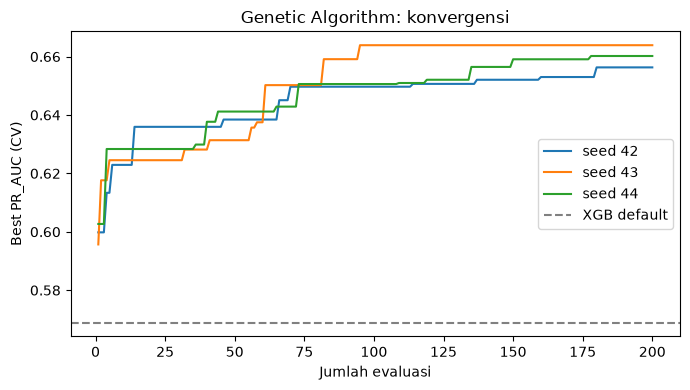

In [39]:
ringkas_ga = []
for seed, ev in ga_runs.items():
    h = pd.DataFrame(ev.history)
    b = h.loc[h["score"].idxmax()]
    ringkas_ga.append({"Seed": seed, "Best PR_AUC (CV)": b["score"], "F1": b["F1"],
                       "Recall": b["Recall"], "scale_pos_weight": b["scale_pos_weight"],
                       "max_depth": b["max_depth"], "learning_rate": b["learning_rate"],
                       "n_estimators": b["n_estimators"]})
ringkas_ga = pd.DataFrame(ringkas_ga)
display(ringkas_ga.round(3))
print(f"Rata-rata best: {ringkas_ga['Best PR_AUC (CV)'].mean():.4f} ± {ringkas_ga['Best PR_AUC (CV)'].std():.4f}")

print(f"\nRiwayat per generasi (seed {SEEDS[0]}):")
display(pd.DataFrame(ga_runs[SEEDS[0]].gen_log).round(4))

fig, ax = plt.subplots(figsize=(7, 4))
for seed, ev in ga_runs.items():
    s = pd.Series([h["score"] for h in ev.history]).cummax()
    ax.plot(range(1, len(s) + 1), s, label=f"seed {seed}")
ax.axhline(hasil_xgb.loc[0, "PR_AUC"], color="gray", ls="--", label="XGB default")
ax.set_xlabel("Jumlah evaluasi"); ax.set_ylabel(f"Best {FITNESS_METRIC} (CV)")
ax.set_title("Genetic Algorithm: konvergensi"); ax.legend(); plt.tight_layout(); plt.show()

##### Ensemble: Voting dan Stacking

In [58]:
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold

def params_terbaik(ev):
    """Hyperparameter dengan skor fitness tertinggi dari satu run pencarian."""
    h = pd.DataFrame(ev.history)
    b = h.loc[h["score"].idxmax()]
    return {k: (int(round(b[k])) if SEARCH_SPACE[k][0] == "int" else float(b[k]))
            for k in SEARCH_SPACE}

# Seed GA terpilih berdasarkan skor CV pada data latih (data uji tidak dipakai)
skor_ga = {s: max(h["score"] for h in ga_runs[s].history) for s in SEEDS}
seed_ga = max(skor_ga, key=skor_ga.get)
params_ga = params_terbaik(ga_runs[seed_ga])
print("Skor CV pencarian per seed GA:", {k: round(v, 4) for k, v in skor_ga.items()})
print("Seed GA terpilih:", seed_ga)

kandidat_ens = {
    "LogReg": make_model("LogReg"),
    f"XGB-GA (seed {seed_ga})": make_xgb(params_ga),
    "Voting (LogReg + XGB-GA)": VotingClassifier(
        estimators=[("lr", make_model("LogReg")), ("xgb", make_xgb(params_ga))],
        voting="soft"),
    "Stacking (LogReg + XGB-GA + RF)": StackingClassifier(
        estimators=[("lr", make_model("LogReg")), ("xgb", make_xgb(params_ga)),
                    ("rf", make_model("RandForest"))],
        final_estimator=LogisticRegression(max_iter=2000, random_state=SEED),
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
        stack_method="predict_proba"),
}
print("Model yang dibandingkan:", list(kandidat_ens))

Skor CV pencarian per seed GA: {42: np.float64(0.6563), 43: np.float64(0.6639), 44: np.float64(0.6602)}
Seed GA terpilih: 43
Model yang dibandingkan: ['LogReg', 'XGB-GA (seed 43)', 'Voting (LogReg + XGB-GA)', 'Stacking (LogReg + XGB-GA + RF)']


##### Evaluasi Pada CV Baru

In [59]:
cv_baru = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=123)

rows = []
for nama, model in kandidat_ens.items():
    res = cross_validate(build_ens_pipeline(model), X_train, y_train,
                         cv=cv_baru, scoring=SCORING, n_jobs=1)
    r = {m: res[f"test_{m}"].mean() for m in SCORING}
    r.update({f"{m}_std": res[f"test_{m}"].std() for m in SCORING})
    r["Model"] = nama
    rows.append(r)
cv_ens = pd.DataFrame(rows)

tampil = cv_ens[["Model"]].copy()
for m in ["Recall", "F1", "PR_AUC", "ROC_AUC"]:
    tampil[m] = cv_ens.apply(lambda r: f"{r[m]:.3f} ± {r[m+'_std']:.3f}", axis=1)
display(tampil)

,Model,Recall,F1,PR_AUC,ROC_AUC
0,LogReg,0.442 ± 0.065,0.550 ± 0.055,0.642 ± 0.048,0.834 ± 0.037
1,XGB-GA (seed 43),0.368 ± 0.053,0.500 ± 0.057,0.632 ± 0.058,0.829 ± 0.044
2,Voting (LogReg + XGB-GA),0.407 ± 0.070,0.539 ± 0.064,0.665 ± 0.052,0.841 ± 0.041
3,Stacking (LogReg + XGB-GA + RF),0.426 ± 0.067,0.554 ± 0.061,0.662 ± 0.054,0.841 ± 0.040


##### Evaluasi Pada Data Uji

In [60]:
def cari_threshold_ens(model, min_recall=0.5):
    oof = oof_proba(build_ens_pipeline(model), X_train, y_train)
    best_thr, best_f1 = 0.5, -1
    for thr in np.arange(0.05, 0.96, 0.01):
        m = compute_metrics(y_train, oof, thr)
        if m["Recall"] >= min_recall and m["F1"] > best_f1:
            best_thr, best_f1 = float(thr), m["F1"]
    return best_thr

yt = y_test.values
rng_boot = np.random.default_rng(SEED)
idx_boot = [rng_boot.integers(0, len(yt), len(yt)) for _ in range(1000)]

rows_05, rows_thr, proba_uji = [], [], {}
for nama, model in kandidat_ens.items():
    pipe = build_ens_pipeline(model).fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    proba_uji[nama] = proba
    thr = cari_threshold_ens(model)

    pr = [average_precision_score(yt[ib], proba[ib]) for ib in idx_boot if yt[ib].sum() > 0]
    ci = f"[{np.percentile(pr, 2.5):.3f}, {np.percentile(pr, 97.5):.3f}]"

    rows_05.append({"Model": nama, **compute_metrics(y_test, proba, 0.5)})
    rows_thr.append({"Model": nama, "Threshold": thr, **compute_metrics(y_test, proba, thr),
                     "PR_AUC 95% CI": ci})
    print(f"{nama:34s} threshold OOF = {thr:.2f}", flush=True)

metrik_ens = ["Precision", "Recall", "F1", "BalAcc", "ROC_AUC", "PR_AUC"]
print("\n== Data uji, threshold 0.5 ==")
display(pd.DataFrame(rows_05).set_index("Model")[metrik_ens].round(3))
print("== Data uji, threshold hasil OOF ==")
display(pd.DataFrame(rows_thr).set_index("Model")[["Threshold"] + metrik_ens + ["PR_AUC 95% CI"]].round(3))

LogReg                             threshold OOF = 0.40
XGB-GA (seed 43)                   threshold OOF = 0.35
Voting (LogReg + XGB-GA)           threshold OOF = 0.37
Stacking (LogReg + XGB-GA + RF)    threshold OOF = 0.31

== Data uji, threshold 0.5 ==


,Precision,Recall,F1,BalAcc,ROC_AUC,PR_AUC
Model,,,,,,
LogReg,0.593,0.340,0.432,0.648,0.818,0.581
XGB-GA (seed 43),0.765,0.277,0.406,0.630,0.813,0.553
Voting (LogReg + XGB-GA),0.783,0.383,0.514,0.681,0.819,0.591
Stacking (LogReg + XGB-GA + RF),0.720,0.383,0.500,0.677,0.822,0.584


== Data uji, threshold hasil OOF ==


,Threshold,Precision,Recall,F1,BalAcc,ROC_AUC,PR_AUC,PR_AUC 95% CI
Model,,,,,,,,
LogReg,0.40,0.629,0.468,0.537,0.708,0.818,0.581,"[0.437, 0.709]"
XGB-GA (seed 43),0.35,0.512,0.447,0.477,0.683,0.813,0.553,"[0.418, 0.690]"
Voting (LogReg + XGB-GA),0.37,0.583,0.447,0.506,0.693,0.819,0.591,"[0.447, 0.722]"
Stacking (LogReg + XGB-GA + RF),0.31,0.558,0.511,0.533,0.717,0.822,0.584,"[0.437, 0.715]"


In [40]:
%pip install optuna shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [41]:
[k for k in globals() if "run" in k.lower() or k in ("X_train","y_train","X_test","y_test")]

['X_train',
 'X_test',
 'y_train',
 'y_test',
 'run_cv',
 'rs_runs',
 'RERUN_GA',
 'ga_runs']

# Optimasi Multi-Objective NSGA-II & Evaluasi Akhir
Objektif (maksimalkan keduanya): PR-AUC dan Recall kelas Attrition, dihitung dengan `run_cv`
yang sama dengan Random Search dan GA (budget 200 evaluasi, seed 42/43/44, population 20).

In [42]:
%pip install xgboost
import time
import xgboost as xgb
from xgboost import XGBClassifier

SEEDS = [42, 43, 44]
BUDGET = 200

SEARCH_SPACE = {
    "n_estimators":     ("int",   50,    500),
    "max_depth":        ("int",   2,     10),
    "learning_rate":    ("log",   0.01,  0.3),
    "subsample":        ("float", 0.5,   1.0),
    "colsample_bytree": ("float", 0.5,   1.0),
    "min_child_weight": ("int",   1,     10),
    "gamma":            ("float", 0.0,   5.0),
    "reg_lambda":       ("log",   0.1,   10.0),
    "reg_alpha":        ("log",   0.001, 10.0),
    "scale_pos_weight": ("float", 1.0,   10.0),
}

def build_ens_pipeline(model, imb=None):
    pre = ColumnTransformer([
        ("num", StandardScaler(), CONT + ORD),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    steps = [("pre", pre)]
    if imb == "smote":
        steps.append(("smote", SMOTE(random_state=SEED)))
    steps.append(("clf", model))
    return ImbPipeline(steps)

def make_xgb(params):
    return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss", **params)

spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight =", round(spw, 3))

Note: you may need to restart the kernel to use updated packages.
scale_pos_weight = 5.189



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
import optuna, shap, os, time
optuna.logging.set_verbosity(optuna.logging.WARNING)
os.makedirs("hasil_search", exist_ok=True)

dibutuhkan = ["X_train", "X_test", "y_train", "y_test", "run_cv", "build_ens_pipeline",
              "make_xgb", "compute_metrics", "SEARCH_SPACE", "SEEDS", "BUDGET", "spw"]
hilang = [n for n in dibutuhkan if n not in globals()]
assert not hilang, f"Jalankan dulu cell di atas, belum ada: {hilang}"
print("Optuna:", optuna.__version__, "| SHAP:", shap.__version__)

Optuna: 5.0.0 | SHAP: 0.51.0


In [44]:
#Fungsi Objektif
def params_from_trial(trial):
    """Search space identik dengan SEARCH_SPACE milik Random Search dan GA."""
    p = {}
    for name, (kind, lo, hi) in SEARCH_SPACE.items():
        if kind == "int":
            p[name] = trial.suggest_int(name, lo, hi)
        elif kind == "log":
            p[name] = trial.suggest_float(name, lo, hi, log=True)
        else:
            p[name] = trial.suggest_float(name, lo, hi)
    return p

def objective(trial):
    params = params_from_trial(trial)
    r = run_cv(build_ens_pipeline(make_xgb(params)), X_train, y_train)
    trial.set_user_attr("F1", r["F1"])
    trial.set_user_attr("Precision", r["Precision"])
    return r["PR_AUC"], r["Recall"]          # dua objektif, keduanya dimaksimalkan

In [45]:
#Menjalankan NSGA-II
def run_nsga2(seed, budget=BUDGET, pop=20):
    sampler = optuna.samplers.NSGAIISampler(population_size=pop, seed=seed)
    study = optuna.create_study(directions=["maximize", "maximize"], sampler=sampler)
    t = time.time()
    study.optimize(objective, n_trials=budget)
    return study, time.time() - t

def study_to_df(study):
    """Format sama dengan rs_seed*.csv dan ga_seed*.csv."""
    rows = [{"eval": t.number + 1, "score": t.values[0], "F1": t.user_attrs["F1"],
             "Recall": t.values[1], **t.params} for t in study.trials]
    return pd.DataFrame(rows)

nsga_runs, nsga_time = {}, {}

In [46]:
#seed 42
seed = 42
nsga_runs[seed], nsga_time[seed] = run_nsga2(seed)
st = nsga_runs[seed]
print(f"Seed {seed}: {len(st.trials)} evaluasi | solusi Pareto = {len(st.best_trials)} | "
      f"{nsga_time[seed]/60:.1f} menit")

Seed 42: 200 evaluasi | solusi Pareto = 13 | 2.7 menit


In [47]:
#seed 43,44
for seed in [43, 44]:
    nsga_runs[seed], nsga_time[seed] = run_nsga2(seed)
    st = nsga_runs[seed]
    print(f"Seed {seed}: {len(st.trials)} evaluasi | solusi Pareto = {len(st.best_trials)} | "
          f"{nsga_time[seed]/60:.1f} menit", flush=True)


Seed 43: 200 evaluasi | solusi Pareto = 14 | 2.2 menit
Seed 44: 200 evaluasi | solusi Pareto = 19 | 2.4 menit


In [48]:
#simpan 
for seed, st in nsga_runs.items():
    study_to_df(st).to_csv(f"hasil_search/nsga2_seed{seed}.csv", index=False)
print("Tersimpan: hasil_search/nsga2_seed42/43/44.csv")

Tersimpan: hasil_search/nsga2_seed42/43/44.csv


In [49]:
#baca hasil RS dan GA
COLS = list(SEARCH_SPACE)

def read_hist(prefix, seed):
    for folder in ["hasil_search", "."]:
        path = f"{folder}/{prefix}_seed{seed}.csv"
        if os.path.exists(path):
            return pd.read_csv(path)
    raise FileNotFoundError(f"{prefix}_seed{seed}.csv tidak ditemukan (taruh di hasil_search/)")

def best_params(df):
    row = df.loc[df["score"].idxmax()]
    p = {k: float(row[k]) for k in COLS}
    for k in ["n_estimators", "max_depth", "min_child_weight"]:
        p[k] = int(round(p[k]))
    return p

rs_hist = {s: read_hist("rs", s) for s in SEEDS}
ga_hist = {s: read_hist("ga", s) for s in SEEDS}
rs_params = {s: best_params(h) for s, h in rs_hist.items()}
ga_params = {s: best_params(h) for s, h in ga_hist.items()}

ringkas_search = pd.DataFrame({
    "RS best PR_AUC (CV)": {s: h["score"].max() for s, h in rs_hist.items()},
    "GA best PR_AUC (CV)": {s: h["score"].max() for s, h in ga_hist.items()},
})
display(ringkas_search.round(4))

,RS best PR_AUC (CV),GA best PR_AUC (CV)
42,0.6386,0.6563
43,0.6514,0.6639
44,0.6334,0.6602


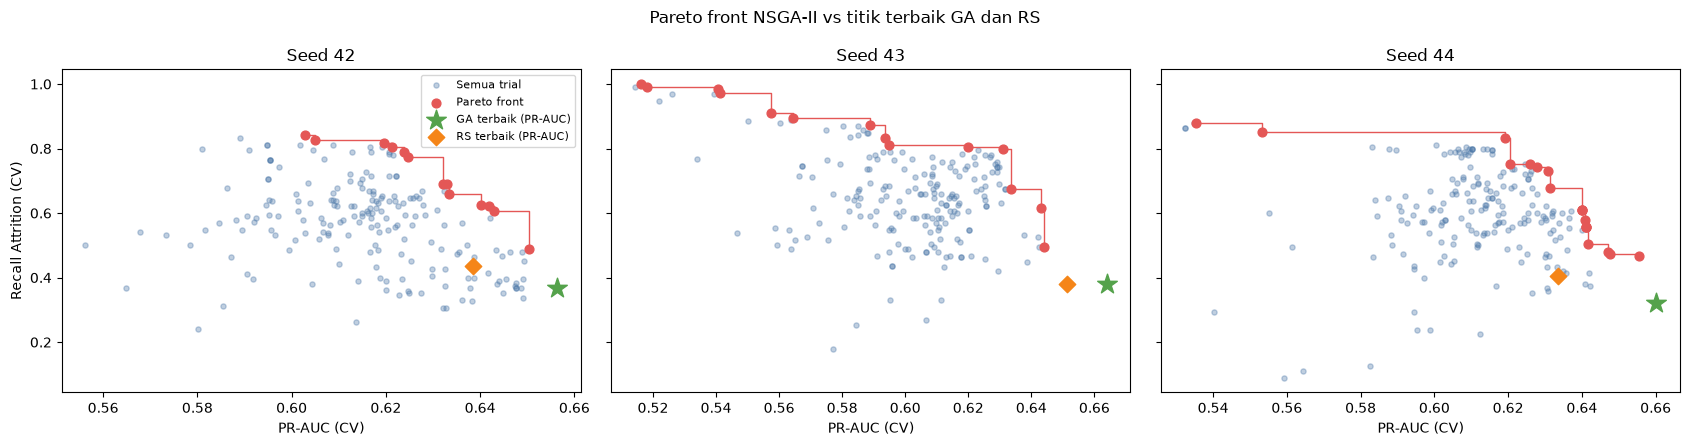

In [50]:
#plot pareto 
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, seed in zip(axes, SEEDS):
    st = nsga_runs[seed]
    semua = np.array([t.values for t in st.trials])
    pareto = np.array([t.values for t in st.best_trials])
    pareto = pareto[np.argsort(pareto[:, 0])]
    ax.scatter(semua[:, 0], semua[:, 1], s=14, alpha=.35, color="#4C78A8", label="Semua trial")
    ax.step(pareto[:, 0], pareto[:, 1], where="post", color="#E45756", lw=1)
    ax.scatter(pareto[:, 0], pareto[:, 1], s=40, color="#E45756", label="Pareto front")
    b = ga_hist[seed].loc[ga_hist[seed]["score"].idxmax()]
    ax.scatter(b["score"], b["Recall"], marker="*", s=220, color="#54A24B", label="GA terbaik (PR-AUC)")
    b = rs_hist[seed].loc[rs_hist[seed]["score"].idxmax()]
    ax.scatter(b["score"], b["Recall"], marker="D", s=70, color="#F58518", label="RS terbaik (PR-AUC)")
    ax.set_title(f"Seed {seed}"); ax.set_xlabel("PR-AUC (CV)")
axes[0].set_ylabel("Recall Attrition (CV)"); axes[0].legend(fontsize=8)
plt.suptitle("Pareto front NSGA-II vs titik terbaik GA dan RS"); plt.tight_layout()
plt.savefig("hasil_search/pareto_front.png", dpi=150); plt.show()

In [51]:
#pilih solusi akhir
MIN_RECALL = 0.50   # syarat bisnis: minimal separuh karyawan yang akan keluar harus terdeteksi

def pilih_solusi(study, min_recall=MIN_RECALL):
    kand = [t for t in study.best_trials if t.values[1] >= min_recall]
    if not kand:
        print(f"  Tidak ada solusi dengan recall >= {min_recall}; pakai F1 tertinggi di seluruh Pareto.")
        kand = study.best_trials
    return max(kand, key=lambda t: t.user_attrs["F1"])    # F1 CV tertinggi

nsga_params, rows = {}, []
for seed, st in nsga_runs.items():
    t = pilih_solusi(st)
    nsga_params[seed] = {k: (int(t.params[k]) if SEARCH_SPACE[k][0] == "int" else float(t.params[k]))
                         for k in COLS}
    rows.append({"Seed": seed, "PR_AUC (CV)": t.values[0], "Recall (CV)": t.values[1],
                 "F1 (CV)": t.user_attrs["F1"], "scale_pos_weight": t.params["scale_pos_weight"],
                 "max_depth": t.params["max_depth"], "n_Pareto": len(st.best_trials)})
display(pd.DataFrame(rows).round(3))

,Seed,PR_AUC (CV),Recall (CV),F1 (CV),scale_pos_weight,max_depth,n_Pareto
0,42,0.643,0.605,0.585,3.508,2,13
1,43,0.643,0.616,0.560,3.956,2,14
2,44,0.642,0.505,0.572,1.855,2,19


In [52]:
#evaluasi pada data test
def eval_test(params):
    pipe = build_ens_pipeline(make_xgb(params)).fit(X_train, y_train)
    return compute_metrics(y_test, pipe.predict_proba(X_test)[:, 1]), pipe

rows, pipes = [], {}
skenario = [("XGB default", {s: {} for s in SEEDS}),
            ("XGB default + spw", {s: {"scale_pos_weight": float(spw)} for s in SEEDS}),
            ("Random Search", rs_params), ("GA", ga_params), ("NSGA-II", nsga_params)]
for nama, pdict in skenario:
    for s in SEEDS:
        m, pipe = eval_test(pdict[s])
        rows.append({"Model": nama, "Seed": s, **m}); pipes[(nama, s)] = pipe

hasil_test = pd.DataFrame(rows)
hasil_test.to_csv("hasil_search/perbandingan_akhir.csv", index=False)

,Precision,Recall,F1,BalAcc,ROC_AUC,PR_AUC
Model,,,,,,
XGB default,0.750 ± 0.000,0.255 ± 0.000,0.381 ± 0.000,0.620 ± 0.000,0.757 ± 0.000,0.485 ± 0.000
XGB default + spw,0.520 ± 0.000,0.277 ± 0.000,0.361 ± 0.000,0.614 ± 0.000,0.737 ± 0.000,0.435 ± 0.000
Random Search,0.663 ± 0.091,0.333 ± 0.081,0.435 ± 0.051,0.649 ± 0.031,0.804 ± 0.009,0.548 ± 0.009
GA,0.733 ± 0.120,0.248 ± 0.033,0.368 ± 0.035,0.615 ± 0.014,0.805 ± 0.008,0.544 ± 0.008
NSGA-II,0.488 ± 0.061,0.511 ± 0.093,0.491 ± 0.019,0.702 ± 0.026,0.801 ± 0.003,0.549 ± 0.013


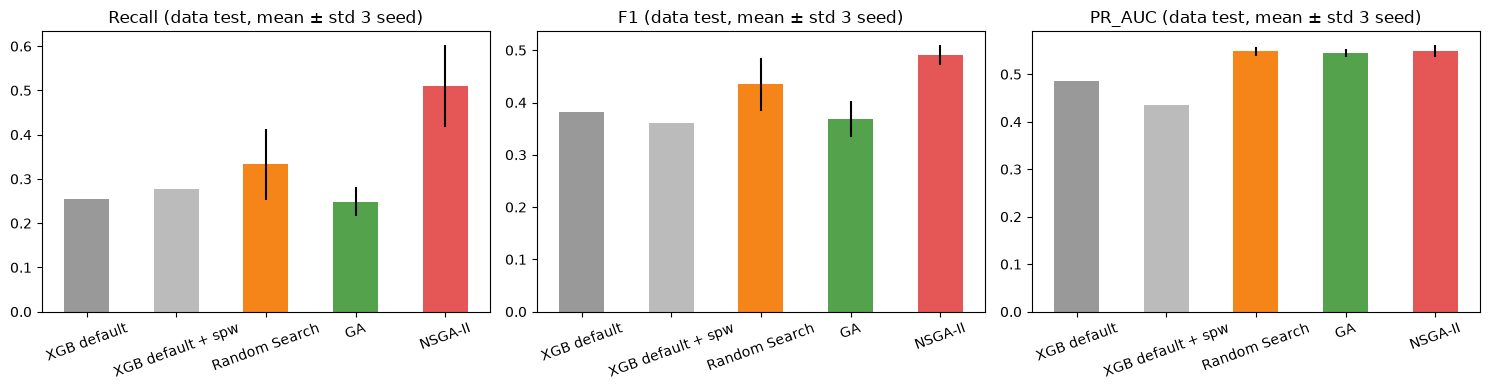

In [53]:
#tabel perbandingan akhir 
metrik = ["Precision", "Recall", "F1", "BalAcc", "ROC_AUC", "PR_AUC"]
urut = [n for n, _ in skenario]
g = hasil_test.groupby("Model")[metrik].agg(["mean", "std"]).loc[urut]
tabel = pd.DataFrame({m: g[m]["mean"].map("{:.3f}".format) + " ± " + g[m]["std"].fillna(0).map("{:.3f}".format)
                      for m in metrik})
display(tabel)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m in zip(axes, ["Recall", "F1", "PR_AUC"]):
    g[m]["mean"].plot(kind="bar", yerr=g[m]["std"].fillna(0), ax=ax, rot=20,
                      color=["#999", "#BBB", "#F58518", "#54A24B", "#E45756"])
    ax.set_title(f"{m} (data test, mean ± std 3 seed)"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig("hasil_search/perbandingan_akhir.png", dpi=150); plt.show()

In [54]:
#tuning threshold probabilitas (untuk NSGA-II seed 42)
def cari_threshold(params, min_recall=0.5):
    """Threshold dengan F1 tertinggi (syarat recall minimal) pada probabilitas out-of-fold data train."""
    oof = oof_proba(build_ens_pipeline(make_xgb(params)), X_train, y_train)
    best_thr, best_f1 = 0.5, -1
    for thr in np.arange(0.05, 0.96, 0.01):
        m = compute_metrics(y_train, oof, thr)
        if m["Recall"] >= min_recall and m["F1"] > best_f1:
            best_thr, best_f1 = float(thr), m["F1"]
    return best_thr

rows = []
for nama, pdict in skenario:
    for s in SEEDS:
        thr = cari_threshold(pdict[s])
        proba = pipes[(nama, s)].predict_proba(X_test)[:, 1]
        rows.append({"Model": nama, "Seed": s, "Threshold": thr, **compute_metrics(y_test, proba, thr)})

hasil_thr = pd.DataFrame(rows)
hasil_thr.to_csv("hasil_search/perbandingan_threshold.csv", index=False)
display(hasil_thr.groupby("Model")[["Threshold"] + metrik].mean().loc[urut].round(3))

,Threshold,Precision,Recall,F1,BalAcc,ROC_AUC,PR_AUC
Model,,,,,,,
XGB default,0.160,0.477,0.447,0.462,0.677,0.757,0.485
XGB default + spw,0.120,0.323,0.447,0.375,0.634,0.737,0.435
Random Search,0.300,0.486,0.589,0.532,0.735,0.804,0.548
GA,0.333,0.515,0.511,0.508,0.709,0.805,0.544
NSGA-II,0.497,0.487,0.511,0.492,0.702,0.801,0.549


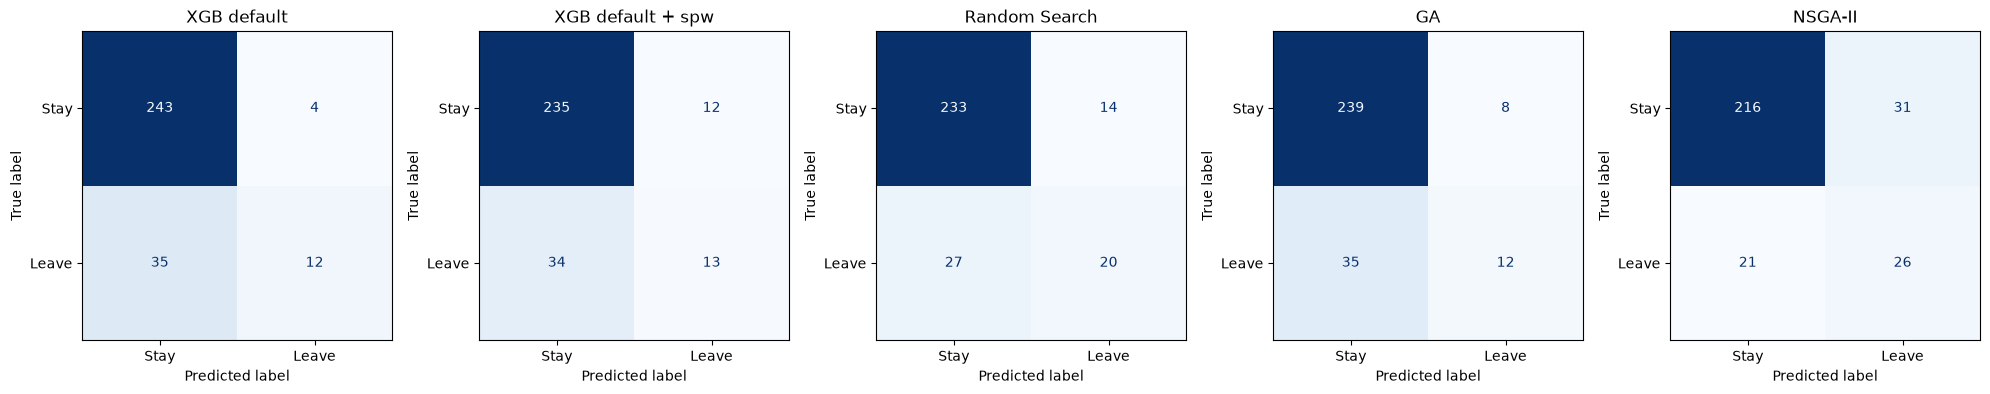

In [55]:
#confusion matrix
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, nama in zip(axes, urut):
    pred = pipes[(nama, 42)].predict(X_test)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stay", "Leave"]
                           ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nama)
plt.tight_layout(); plt.savefig("hasil_search/confusion_matrix.png", dpi=150); plt.show()

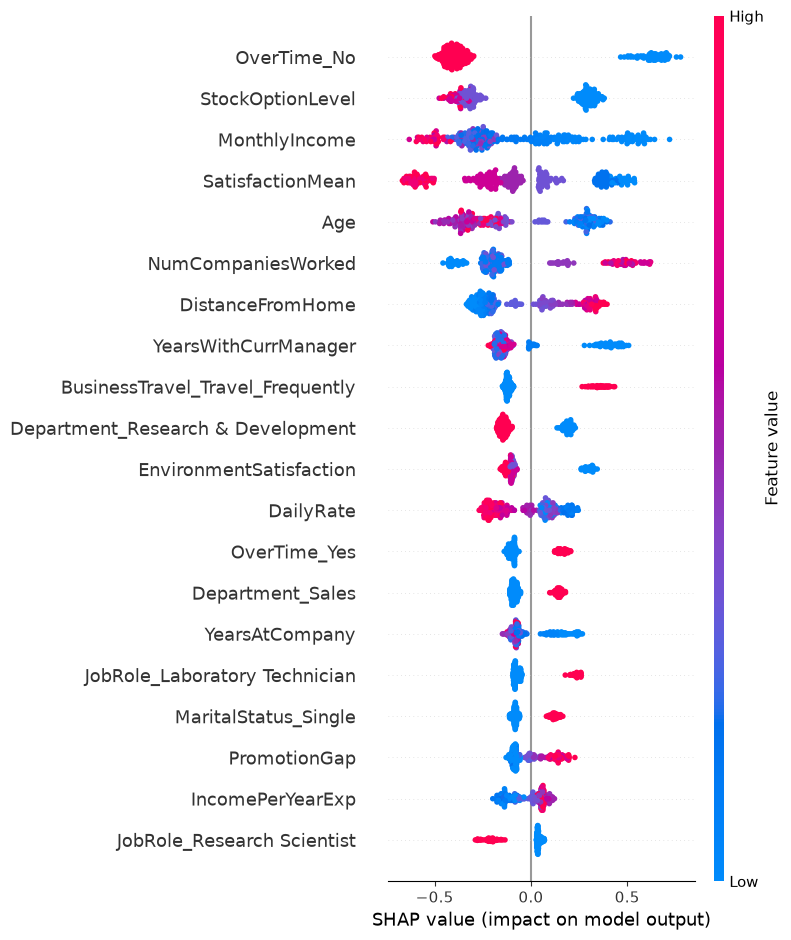

In [56]:
#SHAP summary
pipe = pipes[("NSGA-II", 42)]
pre, clf = pipe.named_steps["pre"], pipe.named_steps["clf"]
nama_fitur = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
Xt = pre.transform(X_test)
sv = shap.TreeExplainer(clf).shap_values(Xt)

shap.summary_plot(sv, Xt, feature_names=nama_fitur, show=False)
plt.tight_layout(); plt.savefig("hasil_search/shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()

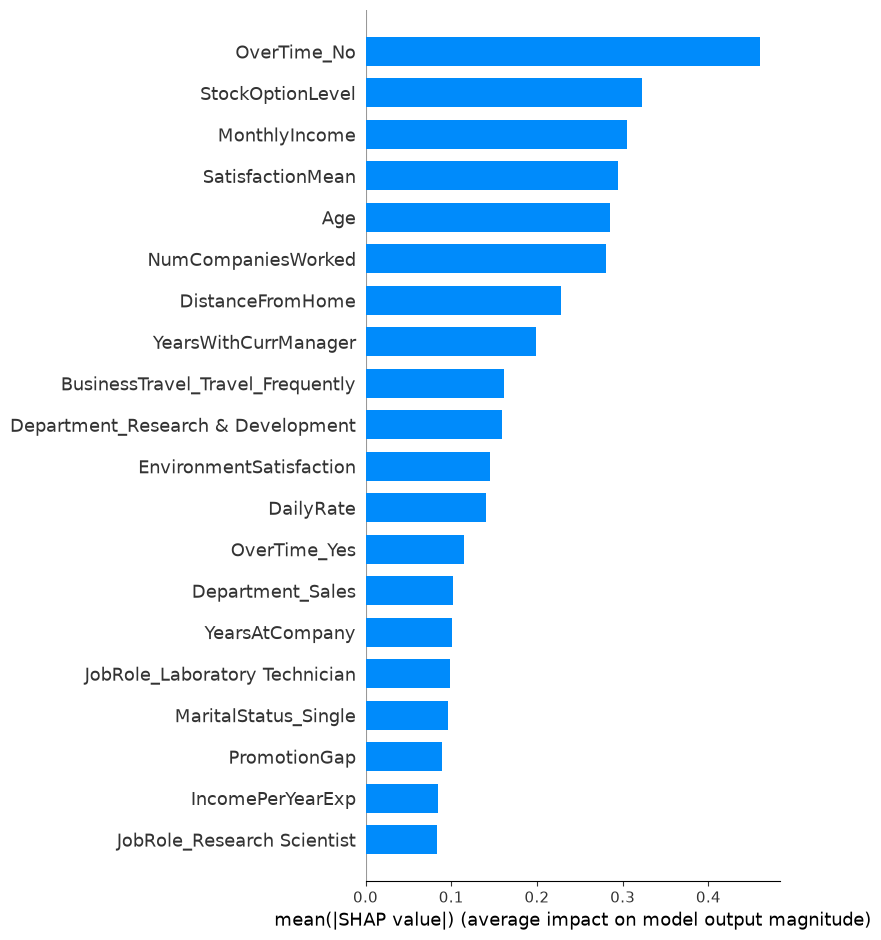

,mean |SHAP|
OverTime_No,0.4605
StockOptionLevel,0.3222
MonthlyIncome,0.3048
SatisfactionMean,0.2941
Age,0.2856
NumCompaniesWorked,0.2803
DistanceFromHome,0.2277
YearsWithCurrManager,0.1988
BusinessTravel_Travel_Frequently,0.1615
Department_Research & Development,0.1590


In [57]:
#SHAP bar dan tabel top 10
shap.summary_plot(sv, Xt, feature_names=nama_fitur, plot_type="bar", show=False)
plt.tight_layout(); plt.savefig("hasil_search/shap_bar.png", dpi=150, bbox_inches="tight"); plt.show()

top = (pd.Series(np.abs(sv).mean(0), index=nama_fitur).sort_values(ascending=False).head(10))
display(top.round(4).to_frame("mean |SHAP|"))

## Analisis Pareto Front dan Perbandingan Akhir

### 1. Membaca Pareto front NSGA-II

Setiap titik merah adalah satu konfigurasi XGBoost yang tidak bisa diperbaiki di satu objektif (PR-AUC atau Recall) tanpa mengorbankan objektif lainnya. Jumlah solusi Pareto: **12 (seed 42), 18 (seed 43), dan 8 (seed 44)**.

- **Trade-off PR-AUC vs Recall terlihat jelas.** Di ujung kanan front, PR-AUC tertinggi (sekitar 0,65-0,66) tetapi recall hanya sekitar 0,40-0,49. Bergerak ke kiri, recall naik tajam.
- **Daerah "lutut" (knee) ada di PR-AUC sekitar 0,64.** Dari ujung kanan ke lutut, PR-AUC hanya turun sekitar 0,01-0,02, tetapi recall naik dari sekitar 0,4-0,5 menjadi sekitar 0,63-0,70. Lebih ke kiri lagi, kenaikan recall menjadi mahal. Contohnya pada seed 42, recall 0,85 baru tercapai dengan PR-AUC sekitar 0,58.
- **Titik terbaik Random Search (belah ketupat oranye) berada di bawah front pada ketiga seed**, artinya selalu ada solusi NSGA-II yang lebih baik di kedua objektif sekaligus.
- **Titik terbaik GA (bintang hijau) ada di sisi kanan bawah**: PR-AUC tertinggi tetapi recall hanya sekitar 0,32-0,38. Pada seed 43 dan 44 GA unggul tipis di PR-AUC (selisih kurang dari 0,01), namun recall-nya jauh lebih rendah. Pada seed 42 titik GA justru didominasi front.

### 2. Solusi akhir yang dipilih

Aturan pemilihan (hanya memakai CV di data train): dari solusi Pareto dengan **Recall CV >= 0,50**, diambil yang **F1 CV tertinggi**. Ketiga solusi terpilih jatuh di area lutut:

| Seed | PR-AUC (CV) | Recall (CV) | F1 (CV) | scale_pos_weight | max_depth |
|---|---|---|---|---|---|
| 42 | 0,642 | 0,700 | 0,539 | 5,60 | 2 |
| 43 | 0,638 | 0,663 | 0,554 | 5,86 | 2 |
| 44 | 0,644 | 0,626 | 0,593 | 5,04 | 6 |
| **Rata-rata** | **0,641** | **0,663** | **0,562** | | |

Sebagai pembanding, rata-rata hasil terbaik GA di CV adalah PR-AUC 0,660 dengan recall sekitar 0,36, sedangkan Random Search PR-AUC 0,641 dengan recall sekitar 0,41. Dengan mengorbankan sekitar 0,02 PR-AUC dibanding GA, NSGA-II hampir menggandakan recall.

Semua solusi NSGA-II memakai `scale_pos_weight` sekitar 5-6, mendekati rasio kelas di data train (sekitar 5,2 : 1). Ini masuk akal: untuk menaikkan recall, model perlu memberi bobot lebih pada kelas Leave.

### 3. Perbandingan akhir di data test

Rata-rata 3 seed. Threshold dicari di data train (probabilitas out-of-fold), lalu dipakai di data test.

| Model | Threshold | Precision | Recall | F1 | BalAcc | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|---|
| XGB default | 0,140 | 0,457 | 0,447 | 0,452 | 0,673 | 0,758 | 0,488 |
| XGB default + spw | 0,190 | 0,388 | 0,404 | 0,396 | 0,641 | 0,744 | 0,474 |
| Random Search | 0,333 | 0,522 | 0,532 | **0,526** | **0,719** | 0,795 | 0,528 |
| GA | 0,357 | **0,575** | 0,454 | 0,505 | 0,695 | **0,803** | 0,543 |
| NSGA-II | 0,550 | 0,453 | **0,546** | 0,494 | 0,710 | 0,800 | **0,552** |

Temuan utama:

1. **Optimasi hyperparameter jelas membantu.** Dibanding XGB default, ketiga metode optimasi menaikkan ROC-AUC dari 0,758 menjadi sekitar 0,80 dan PR-AUC dari 0,488 menjadi 0,53-0,55.
2. **NSGA-II unggul di PR-AUC (0,552) dan Recall (0,546).** Ini sesuai tujuan kedua objektifnya.
3. **Random Search unggul tipis di F1 dan balanced accuracy, GA di ROC-AUC dan Precision.** Selisih antar ketiga metode kecil (sekitar 0,01-0,03). Data test hanya 294 baris dengan sekitar 47 karyawan yang keluar, sehingga satu orang saja menggeser recall sekitar 2 poin. Perbedaan sekecil itu tidak cukup kuat untuk menyatakan satu metode paling baik.
4. **XGB default + scale_pos_weight justru lebih buruk dari default.** Pembobotan kelas dan tuning threshold sama-sama menggeser probabilitas, sehingga efeknya tumpang tindih.
5. **F1 NSGA-II di data test (0,494) lebih rendah dari F1 di CV (0,562).** Solusinya dipilih dengan F1 CV tertinggi, sehingga angka CV-nya cenderung optimistis. Ini efek seleksi yang wajar.
6. **Threshold berbeda-beda antar model (0,14 sampai 0,55).** Model dengan `scale_pos_weight` besar (NSGA-II) menghasilkan probabilitas yang lebih tinggi, sehingga threshold optimalnya ikut naik.

### 4. Confusion matrix (seed 42, threshold 0,5)

Data test: 247 karyawan Stay dan 47 karyawan Leave.

| Model | Leave terdeteksi (dari 47) | Salah tandai Leave (dari 247 Stay) |
|---|---|---|
| XGB default | 11 | 5 |
| XGB default + spw | 15 | 11 |
| Random Search | 15 | 15 |
| GA | 10 | 7 |
| **NSGA-II** | **33** | 47 |

Pada threshold 0,5, model default, RS, dan GA hanya menangkap 10-15 dari 47 karyawan yang keluar (sekitar 21-32%). NSGA-II menangkap 33 dari 47 (sekitar 70%), dengan konsekuensi 47 karyawan yang sebenarnya bertahan ikut ditandai berisiko (precision sekitar 41%). Pilihan model akhirnya bergantung pada biaya: kehilangan satu karyawan yang sebenarnya bisa dipertahankan, atau biaya intervensi untuk satu karyawan yang ternyata tidak berencana keluar.

## Interpretasi SHAP dan Kesimpulan Bagian NSGA-II

### 1. Interpretasi SHAP

SHAP dihitung pada model NSGA-II (seed 42) terhadap data test. Cara membaca grafik:
- **Sumbu x positif** berarti fitur itu mendorong prediksi ke arah **Leave**, sedangkan negatif mendorong ke **Stay**.
- **Warna** menunjukkan nilai fitur (merah = tinggi, biru = rendah). Untuk fitur one-hot (misalnya `OverTime_Yes`), merah berarti kondisi tersebut berlaku.
- **Urutan** pada grafik batang menunjukkan fitur yang rata-rata paling berpengaruh.

Faktor paling berpengaruh dan artinya:

| Fitur | Pola yang dipelajari model | Makna bagi HR |
|---|---|---|
| StockOptionLevel | Level rendah mendorong Leave, level tinggi mendorong Stay | Opsi saham/insentif jangka panjang berkaitan dengan retensi |
| OverTime (Yes/No) | Lembur mendorong Leave, tidak lembur mendorong Stay | Beban lembur adalah salah satu pemicu terkuat. `OverTime_No` dan `OverTime_Yes` adalah dua sisi variabel yang sama, sehingga pengaruh gabungannya adalah yang terbesar |
| SatisfactionMean | Kepuasan rendah mendorong Leave | Fitur turunan rata-rata kepuasan kerja, lingkungan, hubungan, dan work-life balance terbukti berguna |
| Age | Usia muda mendorong Leave | Karyawan muda lebih mudah berpindah |
| MonthlyIncome | Gaji rendah mendorong Leave | Kompensasi rendah meningkatkan risiko |
| NumCompaniesWorked | Pernah di banyak perusahaan mendorong Leave | Riwayat sering berpindah kerja |
| YearsWithCurrManager | Waktu singkat dengan manajer saat ini mendorong Leave | Pergantian manajer atau masa awal kerja rentan |
| DistanceFromHome | Jarak jauh mendorong Leave | Beban perjalanan harian |
| BusinessTravel_Travel_Frequently | Sering dinas luar mendorong Leave | Mobilitas kerja tinggi menambah risiko |
| Department / JobRole | Sales dan Laboratory Technician mendorong Leave, R&D dan Research Scientist cenderung mendorong Stay | Risiko berbeda antar departemen dan jabatan |
| YearsSinceLastPromotion | Lama tidak dipromosikan mendorong Leave | Stagnasi karier |

Catatan penting:
- SHAP menunjukkan **pola yang dipelajari model**, bukan hubungan sebab-akibat. Misalnya, kita tidak bisa menyimpulkan bahwa menaikkan gaji pasti menurunkan attrition.
- `DailyRate` masuk 11 fitur teratas, padahal secara konsep fitur ini hampir tidak berhubungan dengan attrition (di EDA kelompok, nilainya dinilai hampir acak). Kemungkinan model menangkap noise, jadi interpretasinya sebaiknya tidak dipakai untuk keputusan HR.
- Hasil SHAP hanya dari satu seed dan satu model, sehingga urutan fitur bisa sedikit berubah pada seed lain.

### 2. Kesimpulan

1. **Optimasi hyperparameter meningkatkan performa model** dibanding XGBoost default: ROC-AUC naik dari 0,758 menjadi sekitar 0,80 dan PR-AUC dari 0,488 menjadi 0,53-0,55 di data test.
2. **NSGA-II menghasilkan Pareto front** yang menunjukkan trade-off nyata antara PR-AUC dan Recall. Solusi yang dipilih (area lutut) mencapai PR-AUC CV sekitar 0,64 dengan recall CV sekitar 0,66, dibanding GA yang PR-AUC-nya sekitar 0,66 tetapi recall hanya sekitar 0,36.
3. **Di data test, NSGA-II memiliki PR-AUC dan Recall tertinggi** (0,552 dan 0,546), sedangkan RS dan GA unggul tipis di metrik lain. Selisih antar ketiga metode kecil dan belum cukup kuat secara statistik untuk menyatakan satu metode paling unggul.
4. **Keunggulan utama NSGA-II adalah fleksibilitas**: HR bisa memilih titik di Pareto front sesuai kebutuhan, yaitu recall tinggi untuk menjangkau lebih banyak karyawan berisiko, atau precision lebih tinggi untuk menghemat biaya intervensi. RS dan GA tidak memberikan pilihan ini.
5. **Faktor risiko attrition terkuat** menurut SHAP: kurangnya stock option, lembur, kepuasan kerja rendah, usia muda, gaji rendah, dan riwayat sering berpindah perusahaan.

### 3. Keterbatasan dan saran

- **Data test kecil** (294 baris, sekitar 47 karyawan yang keluar), sehingga metrik di data test bervariasi cukup besar. Disarankan memakai repeated cross-validation atau interval kepercayaan untuk pembanding yang lebih kuat.
- **Budget 200 evaluasi per seed hanya menghasilkan perkiraan Pareto front.** Bentuk front berbeda antar seed (seed 44 hanya 8 solusi). Budget atau populasi yang lebih besar, untuk semua metode secara adil, bisa memperjelas front.
- **Pemilihan solusi memakai aturan Recall >= 0,50 dan F1 CV tertinggi.** Aturan ini sebaiknya disesuaikan dengan biaya nyata kehilangan karyawan dan biaya intervensi di organisasi.
- **Saran lanjutan:** menggabungkan fitur membership Fuzzy C-Means dari bagian segmentasi ke dalam model XGBoost, lalu menguji apakah PR-AUC meningkat.